# RSM8413: Machine Learning Analytics 
## Group Assignment #2 - eBay Auction Decision Trees
*Team 6 Python Code*

### **[1]: Data Preprocessing**

In [1]:
import pandas as pd

ebay_df = pd.read_excel("eBayAuctions.xlsx", sheet_name="eBay auctions", usecols="A:H")

In [2]:
ebay_df.shape

(1975, 8)

In [3]:
ebay_df.columns

Index(['Category', 'Currency', 'sellerRating', 'Duration', 'endDay',
       'ClosePrice', 'OpenPrice', 'Competitive?'],
      dtype='str')

In [4]:
len(ebay_df)

1975

In [5]:
ebay_df.head()

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
0,Music/Movie/Game,US,37727.0,7.0,Mon,0.01,0.01,0.0
1,Music/Movie/Game,US,37727.0,7.0,Mon,4.26,0.01,1.0
2,SportingGoods,US,34343.0,1.0,Fri,0.11,0.01,1.0
3,SportingGoods,US,27132.0,5.0,Mon,17.01,0.99,1.0
4,SportingGoods,US,27132.0,5.0,Mon,19.02,0.99,1.0


In [6]:
ebay_df.dtypes

Category            str
Currency            str
sellerRating    float64
Duration        float64
endDay              str
ClosePrice      float64
OpenPrice       float64
Competitive?    float64
dtype: object

#### 1A: Initial Preprocessing

First, we check for any null rows in our data. We take the sheet in the Excel file with the data (eBay Auctions) and only take columns A:H to ensure we don't retrieve other unnamed columns.

In [7]:
# number of nulls in each column
ebay_df.isnull().sum()

# show null value rows
print(ebay_df[ebay_df.isnull().any(axis=1)].to_string())

     Category Currency  sellerRating  Duration endDay  ClosePrice  OpenPrice  Competitive?
1972      NaN      NaN           NaN       NaN    NaN         NaN        NaN           NaN
1973      NaN      NaN           NaN       NaN    NaN         NaN        NaN         955.0
1974      NaN      NaN           NaN       NaN    NaN         NaN        NaN        1741.0


After referencing the dataset, the 3 rows that are null are the last 3 rows are aggregations of the data itself and is not part of the dataset. Therefore, it is just a formatting issue and can be dropped. 

In [8]:
clean_ebay_df = ebay_df.dropna().copy()

clean_ebay_df.isnull().sum()

Category        0
Currency        0
sellerRating    0
Duration        0
endDay          0
ClosePrice      0
OpenPrice       0
Competitive?    0
dtype: int64

In [9]:
# check for duplicate rows

# we note that there are duplicate rows. However, there is no ID column to conclude whether or not the auctions are truly repeated. 
# since there is no further identifier, we keep the duplicates. 

clean_ebay_df[clean_ebay_df.duplicated(keep=False)]

,Category,Currency,sellerRating,Duration,endDay,ClosePrice,OpenPrice,Competitive?
53,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
54,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
55,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
56,Music/Movie/Game,EUR,5701.0,10.0,Sun,1.23,1.23,0.0
71,Pottery/Glass,GBP,5292.0,7.0,Thu,1.78,1.78,0.0
...,...,...,...,...,...,...,...,...
1926,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1927,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1928,Pottery/Glass,US,993.0,7.0,Sat,99.99,99.99,0.0
1941,Automotive,US,1364.0,7.0,Tue,128.00,128.00,0.0


In [10]:
# standardize column names 
# lower case + underscore for 2 words, get rid of other characters
clean_ebay_df.columns = (clean_ebay_df.columns.str.replace(r'(?<=[a-z])(?=[A-Z])', '_', regex=True)
                         .str.replace('?', '', regex=False)
                         .str.lower())

#### 1B: Split Train/Test Data

In [11]:
from sklearn.model_selection import train_test_split

features = ["category", "currency", "seller_rating", "duration", "end_day",
            "close_price", "open_price"]

X = clean_ebay_df[features].copy()
y = clean_ebay_df["competitive"].copy()

print("Predictor shape:", X.shape)
print("Target shape:", y.shape)

print("\nData types:")
print(X.dtypes)

Predictor shape: (1972, 7)
Target shape: (1972,)

Data types:
category             str
currency             str
seller_rating    float64
duration         float64
end_day              str
close_price      float64
open_price       float64
dtype: object


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.4,
    random_state=42,
    stratify=y)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Training set: (1183, 7)
Testing set: (789, 7)


We  split the train/test set into 60% (1183 observations) training and 40% test (789 observations). 
We set the fixed random state to 42 to ensure reproducibility of every run. 

We'll use the training set to perform any further preprocessing steps and visualizations to grasp a better understanding of the variable distributions. 

#### 1C: Predictor Distribution Check

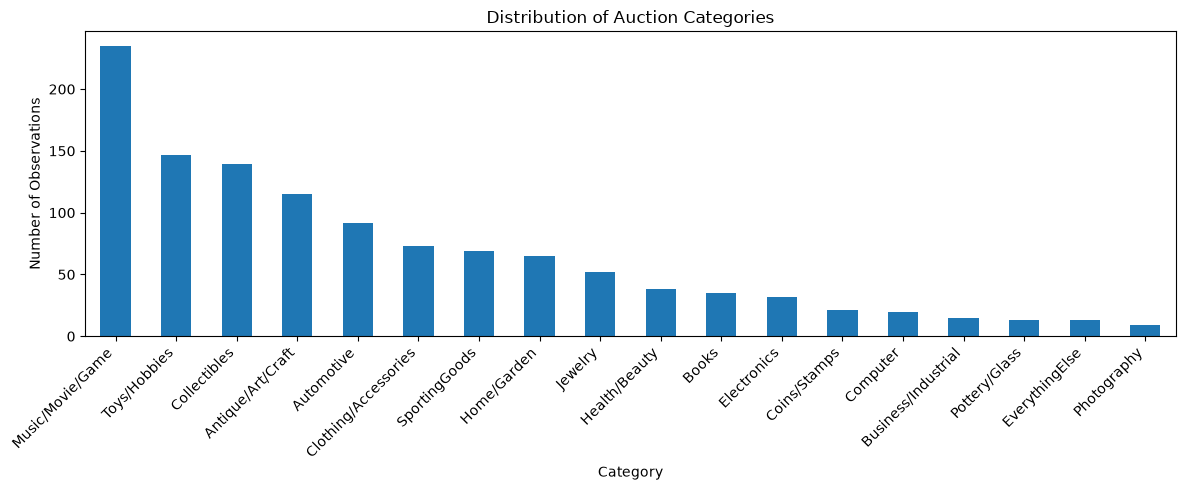

In [13]:
# Category
import matplotlib.pyplot as plt

X_train["category"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Auction Categories")
plt.xlabel("Category")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

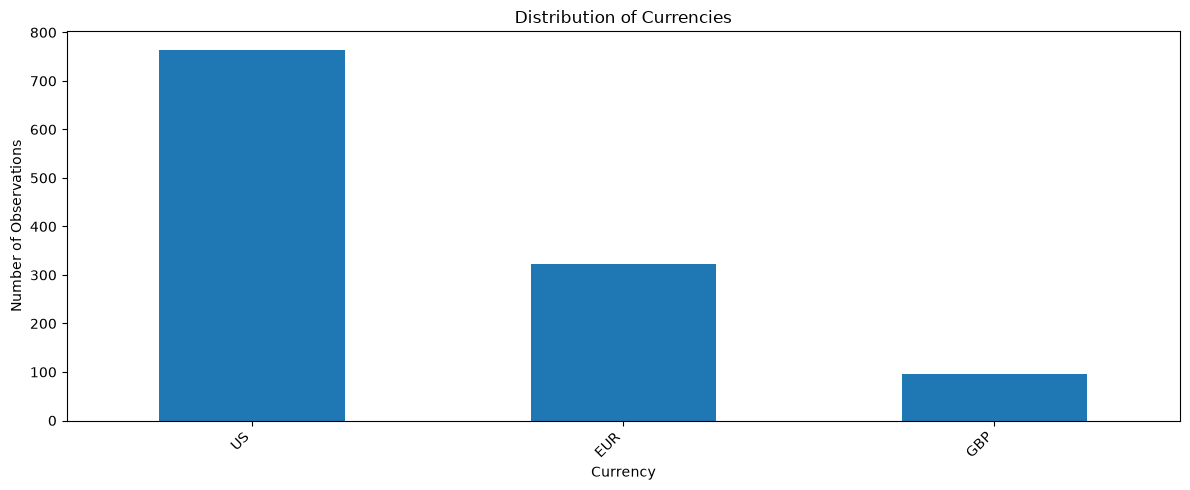

In [14]:
# currency
X_train["currency"].value_counts().plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Currencies")
plt.xlabel("Currency")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

count     1183.000000
mean      3544.847844
std       6058.473199
min          0.000000
25%        578.000000
50%       1719.000000
75%       3380.000000
max      37727.000000
Name: seller_rating, dtype: float64
skew: 3.231030495585379
missing: 0


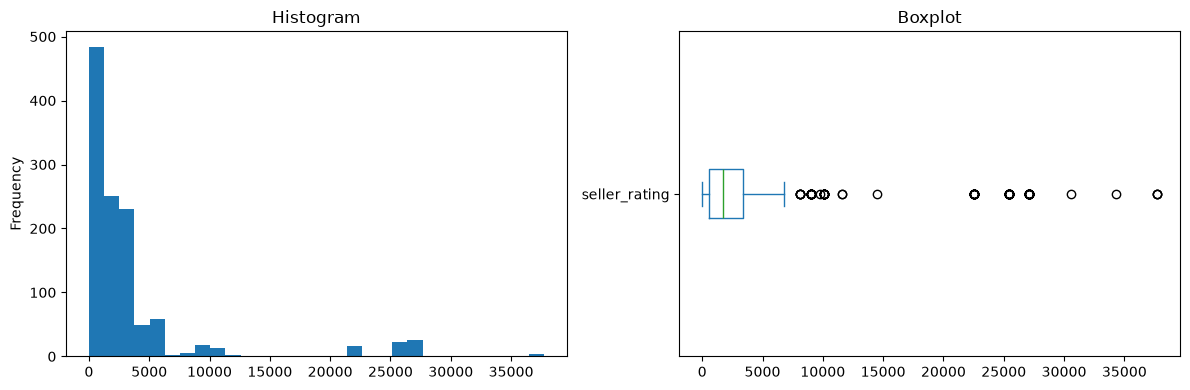

In [15]:
# seller rating 
col = X_train["seller_rating"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

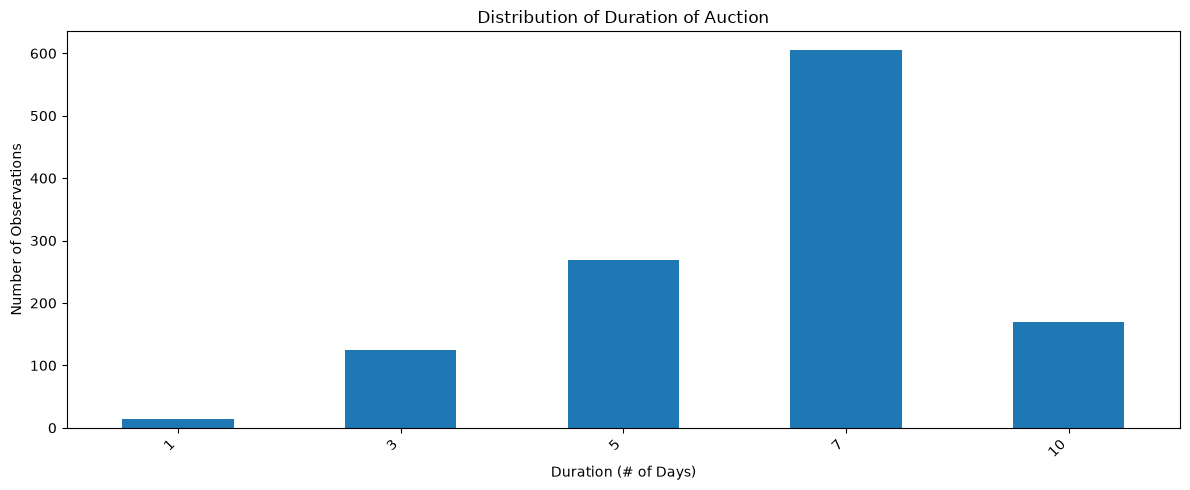

In [16]:
# duration
duration_order = [1, 3, 5, 7, 10]

X_train["duration"].value_counts().reindex(duration_order).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of Duration of Auction")
plt.xlabel("Duration (# of Days)")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

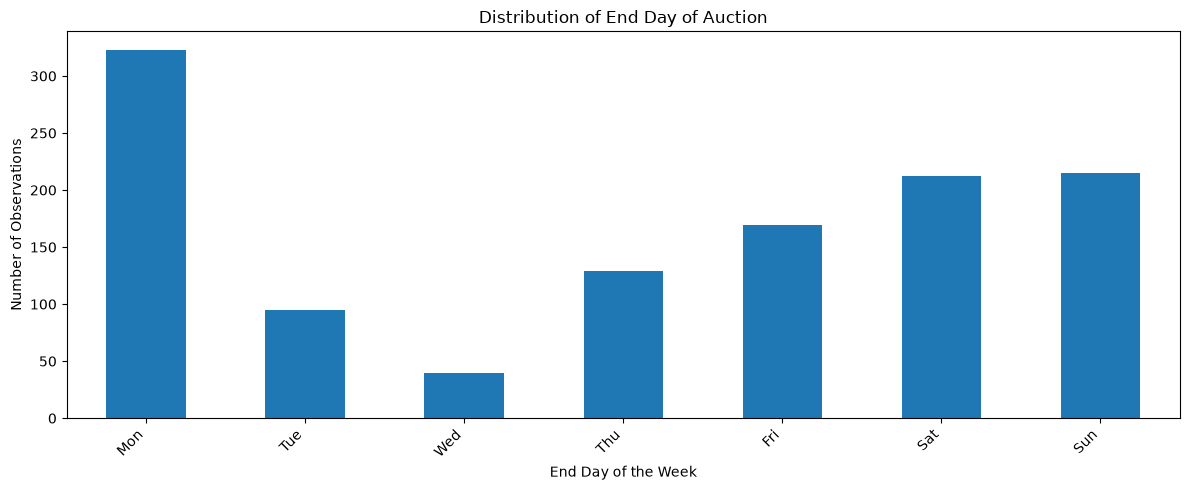

In [17]:
# end day 
day_order = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
X_train["end_day"].value_counts().reindex(day_order).plot(
    kind="bar",
    figsize=(12, 5)
)

plt.title("Distribution of End Day of Auction")
plt.xlabel("End Day of the Week")
plt.ylabel("Number of Observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

count    1183.000000
mean       35.204573
std        86.799829
min         0.010000
25%         4.420000
50%         9.990000
75%        27.000000
max       999.000000
Name: close_price, dtype: float64
skew: 6.1908415212679015
missing: 0


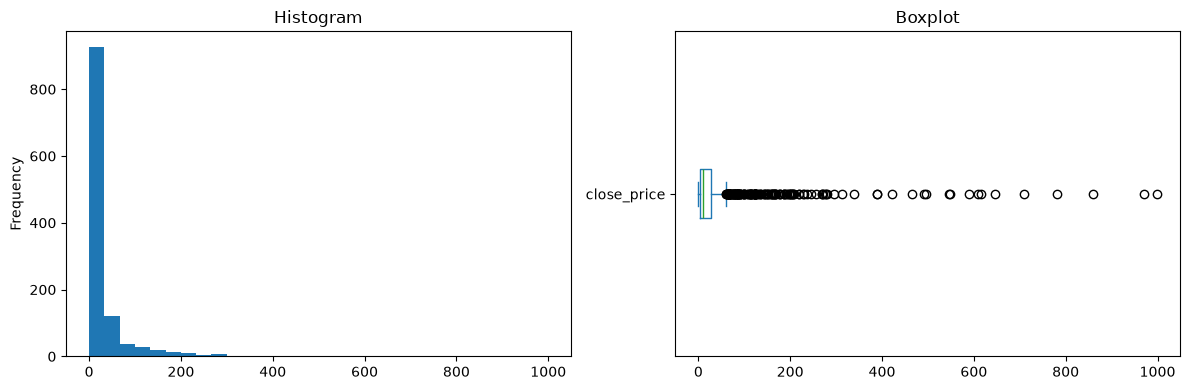

In [18]:
# close price
col = X_train["close_price"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

count    1183.000000
mean       12.520651
std        40.490395
min         0.010000
25%         1.230000
50%         4.440000
75%         9.990000
max       999.000000
Name: open_price, dtype: float64
skew: 15.323018628116992
missing: 0


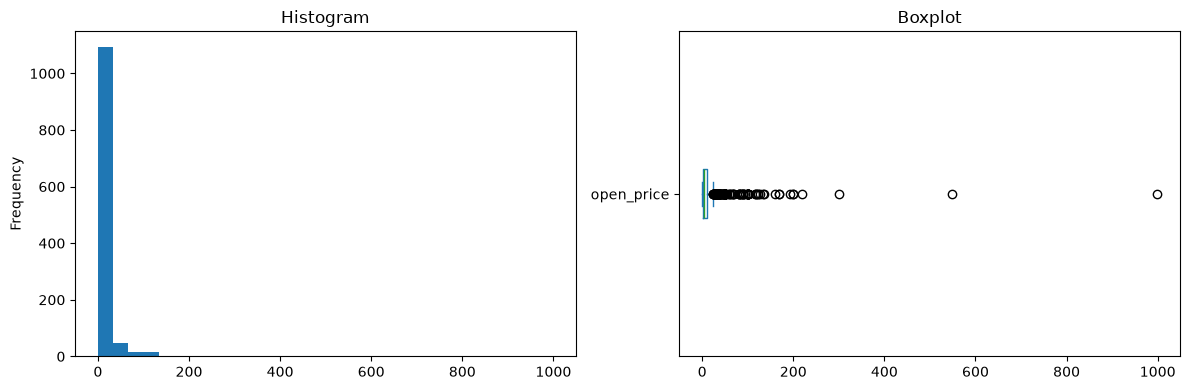

In [19]:
# close price
col = X_train["open_price"]

# Summary stats
print(col.describe())
print("skew:", col.skew())
print("missing:", col.isna().sum())

# Histogram + boxplot
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
col.plot(kind="hist", bins=30, ax=axes[0], title="Histogram")
col.plot(kind="box", vert=False, ax=axes[1], title="Boxplot")
plt.tight_layout()
plt.show()

We conduct an initial distribution analysis to identify potential data quality issues, including numerical predictors with values outside their expected ranges and categorical predictors with inconsistent or non-standardized values.
However, no issues arise when observing the distributions of the variables. 

#### 1D: One-Hot Encoding
Dummy variables are created for the categorical predictors. Numerical predictors are not standardized for the decision tree model, as decision trees use threshold-based splits and are not sensitive to differences in feature scales. In contrast, kNN relies on distance calculations and is sensitive to feature scaling. Therefore, numerical predictors will be standardized when implementing the kNN model later in the analysis.

In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_features = [
    "category",
    "currency",
    "end_day",
    "duration"
]

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ],
    remainder="passthrough"
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

# Check processed dataset dimensions
print("Training shape:", X_train_encoded.shape)
print("Testing shape:", X_test_encoded.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

# ensure response is 0,1 
y_train = y_train.astype(int)
y_test = y_test.astype(int)

Training shape: (1183, 36)
Testing shape: (789, 36)

Training target distribution:
competitive
1.0    639
0.0    544
Name: count, dtype: int64


## [2]: Initial Decision Tree

In [21]:
from sklearn.tree import DecisionTreeClassifier, export_graphviz

In [22]:
!pip install graphviz

  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
Using cached graphviz-0.21-py3-none-any.whl (47 kB)


In [23]:
%matplotlib inline

In [24]:
from sklearn.tree import export_text

In [25]:
!pip install dmba

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 3.0 MB/s  0:00:04m0:00:0100:01


In [26]:
from dmba import classificationSummary

In [27]:
#set model hyperparameters
InitialTree = DecisionTreeClassifier(min_samples_leaf=50, random_state=42)

In [28]:
#Fit Decision Tree model
InitialTree.fit(X_train_encoded,y_train)

,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",50
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sample

In [29]:
classificationSummary(y_train, InitialTree.predict(X_train_encoded))

Confusion Matrix (Accuracy 0.8335)

       Prediction
Actual   0   1
     0 482  62
     1 135 504


In [30]:
#accuracy of training prediction
InitialTree.score(X_train_encoded, y_train)

0.8334742180896028

In [31]:
classificationSummary(y_test, InitialTree.predict(X_test_encoded))

Confusion Matrix (Accuracy 0.8200)

       Prediction
Actual   0   1
     0 311  51
     1  91 336


In [32]:
yprediction = InitialTree.predict(X_test_encoded)

In [33]:
#accuracy of testing prediction
InitialTree.score(X_test_encoded, y_test)

0.8200253485424588

Test accuracy is close to training accuracy, meaning that no obvious train and test performance gap.

In [34]:
InitialTree.get_params()

{'ccp_alpha': 0.0,
 'class_weight': None,
 'criterion': 'gini',
 'max_depth': None,
 'max_features': None,
 'max_leaf_nodes': None,
 'min_impurity_decrease': 0.0,
 'min_samples_leaf': 50,
 'min_samples_split': 2,
 'min_weight_fraction_leaf': 0.0,
 'monotonic_cst': None,
 'random_state': 42,
 'splitter': 'best'}

In [35]:
InitialTree.tree_.node_count

31

In [36]:
InitialTree.tree_.max_depth

6

In [37]:
feature_names = preprocessor.get_feature_names_out()

tree_rules = export_text(
    InitialTree,
    feature_names=list(feature_names)
)

print(tree_rules)

|--- remainder__open_price <= 3.72
|   |--- remainder__close_price <= 3.69
|   |   |--- remainder__open_price <= 1.04
|   |   |   |--- class: 1
|   |   |--- remainder__open_price >  1.04
|   |   |   |--- remainder__close_price <= 1.84
|   |   |   |   |--- class: 0
|   |   |   |--- remainder__close_price >  1.84
|   |   |   |   |--- remainder__seller_rating <= 2256.00
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- remainder__seller_rating >  2256.00
|   |   |   |   |   |--- class: 0
|   |--- remainder__close_price >  3.69
|   |   |--- remainder__open_price <= 2.46
|   |   |   |--- class: 1
|   |   |--- remainder__open_price >  2.46
|   |   |   |--- class: 1
|--- remainder__open_price >  3.72
|   |--- remainder__close_price <= 10.00
|   |   |--- remainder__open_price <= 4.93
|   |   |   |--- class: 0
|   |   |--- remainder__open_price >  4.93
|   |   |   |--- remainder__close_price <= 6.99
|   |   |   |   |--- remainder__close_price <= 5.99
|   |   |   |   |   |--- class: 0
|   |

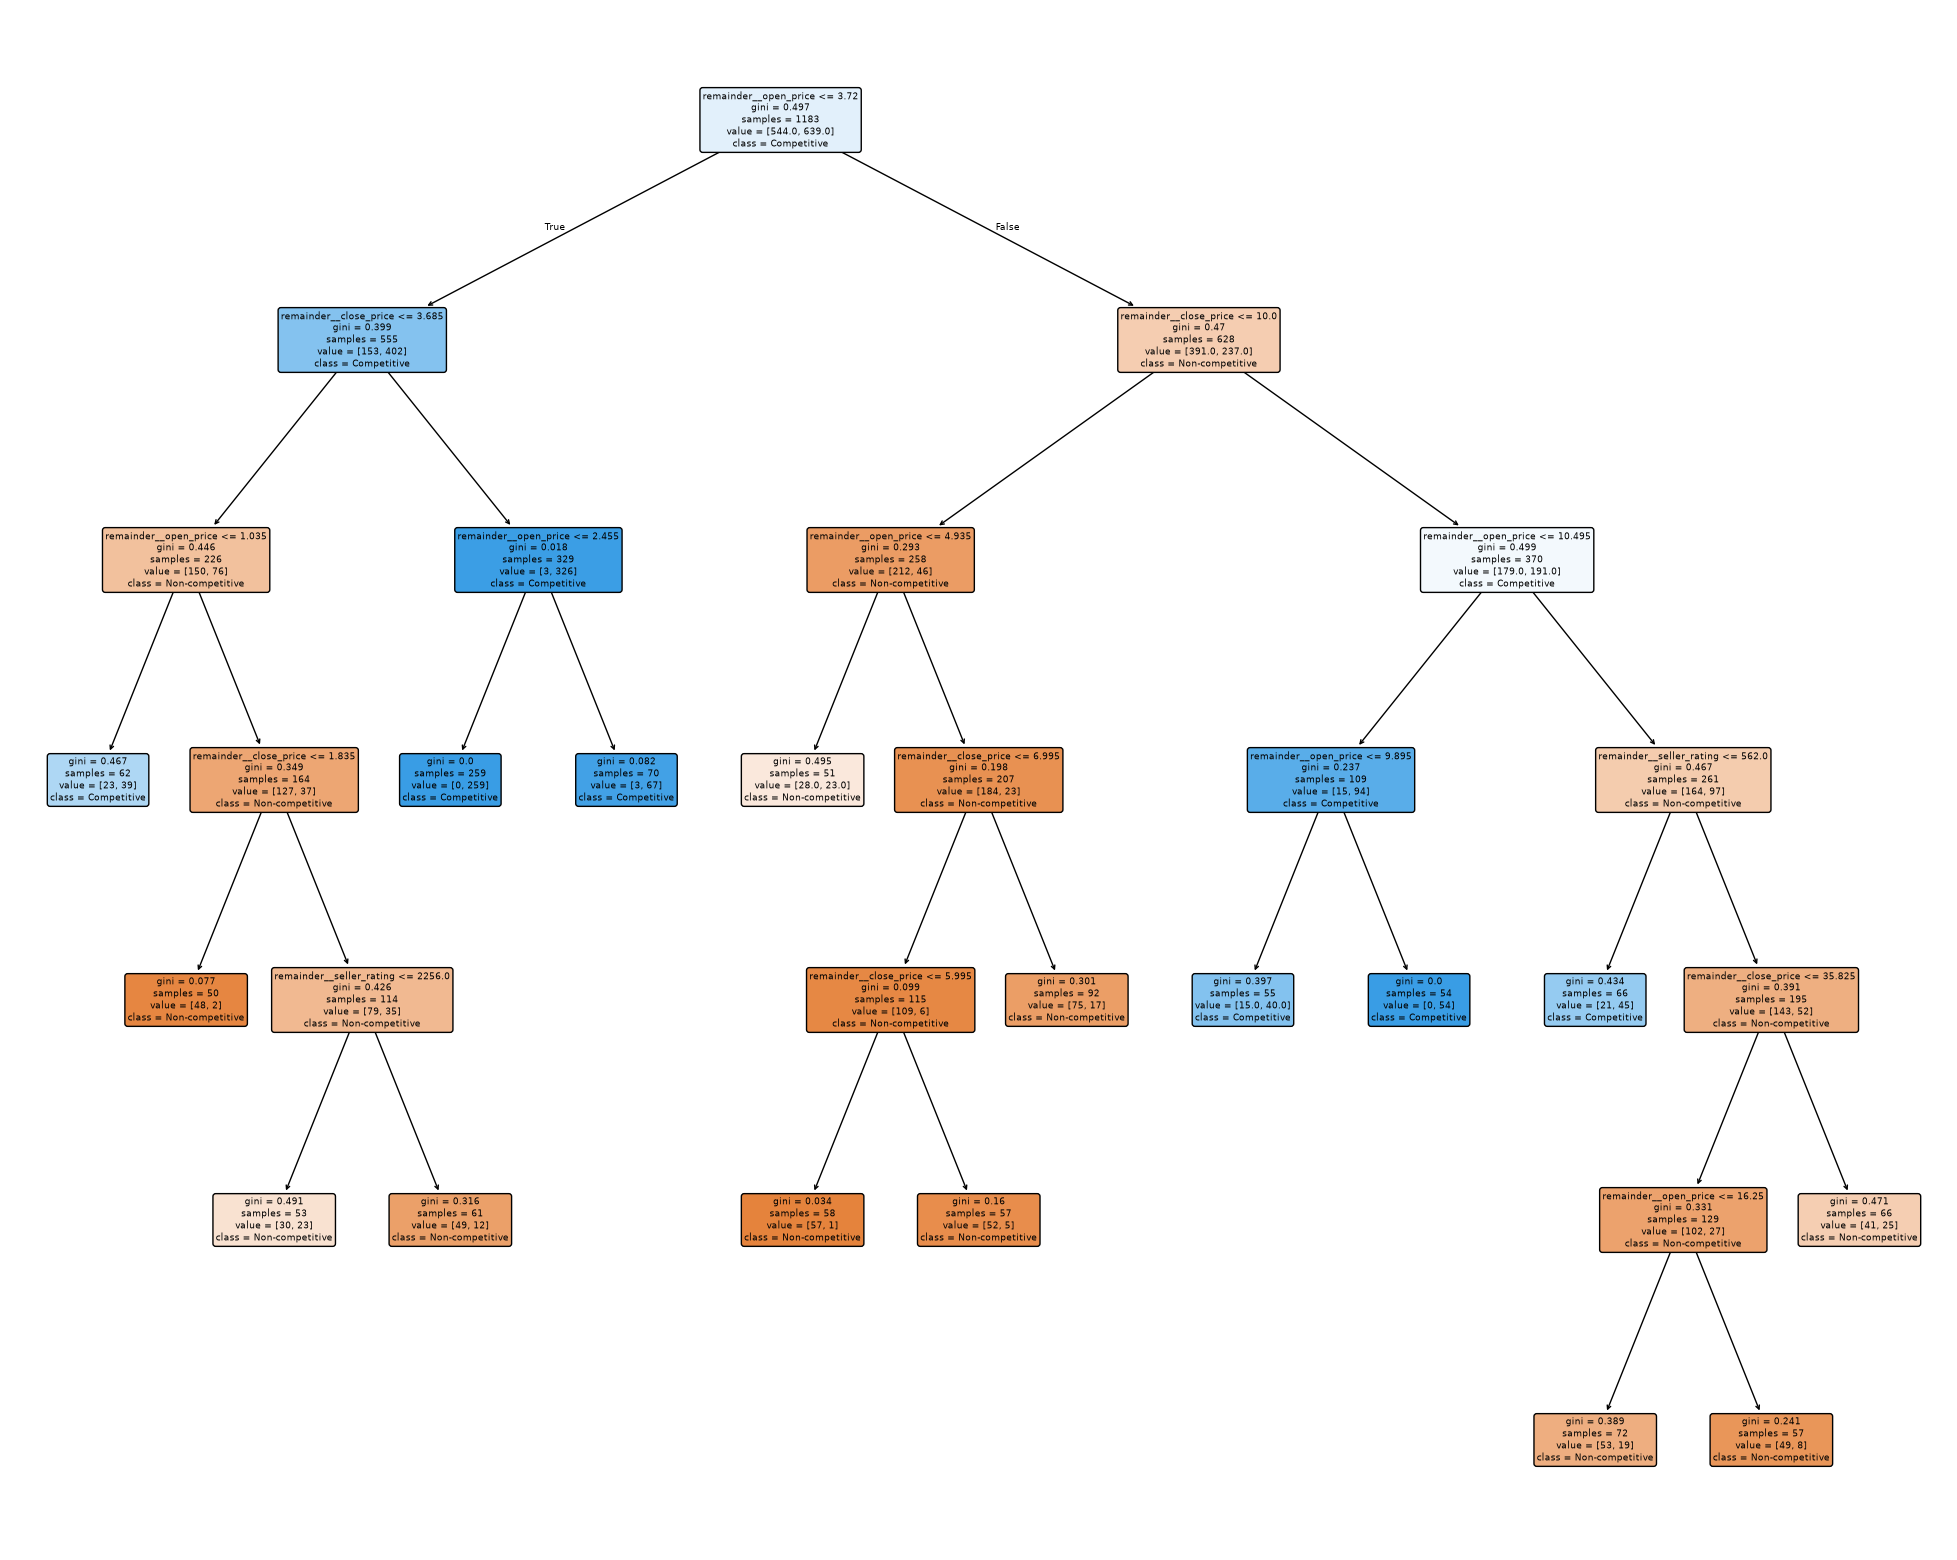

In [38]:
# Plot initial decision tree using the matplotlib approach
import matplotlib.pyplot as plt
from sklearn import tree

fig = plt.figure(figsize=(25, 20))
tree.plot_tree(
    InitialTree,
    feature_names=preprocessor.get_feature_names_out(),
    class_names=["Non-competitive", "Competitive"],
    rounded=True,
    filled=True
)
plt.show()

### Initial Classification Tree: Rules and Interpretation

The initial classification tree was fitted using all available predictors, with a minimum of 50 observations per terminal node to limit overfitting. The resulting tree contains 31 nodes, including 16 terminal nodes, and has a maximum depth of six. The model achieved a training accuracy of 83.35% and a testing accuracy of 82.00%, suggesting relatively consistent predictive performance across the two datasets.

**Classification Rules**

The tree primarily relies on opening price and closing price, with seller rating appearing in a limited number of branches. The root node splits auctions at an opening price of 3.72.

Rule 1:
IF open price <= 1.04 AND close price <= 3.69, THEN Competitive.

Rule 2:
IF open price <= 3.72 AND close price > 3.69, THEN Competitive.

Rule 3:
IF open price > 3.72 AND <= 10.50 AND close price > 10, Then Competitive.

Rule 4:
IF open price > 10.50 AND close price > 10 AND seller_rating <= 562.0, Then Competitive.



**Interesting Findings**

One unexpected finding is that higher seller ratings do not consistently correspond to competitive auctions. Under certain price conditions, auctions associated with lower-rated sellers are classified as competitive, suggesting that seller reputation does not necessarily dominate pricing-related factors in this model.

Additionally, product category, currency, auction duration, and ending day are not selected for any splits, indicating that they provide limited additional classification value under the current model settings.


**Potential Predictor Reduction**

If a small reduction in the number of predictors were required, variables not selected for any splits, such as currency, ending day, duration, or product category, may be reasonable candidates for removal. Their exclusion would simplify the model without changing the current fitted tree's decision rules, although the model should be refitted and evaluated to verify its performance.

But more importantly, closing price is only observable after an auction ends. Therefore, despite its predictive value in the initial model, it should be excluded when developing a practical model for predicting the competitiveness of a new auction.


### [3]: Second Tree Model

In [39]:
#Model Fit 2: Remove predictors unavailable before auction ends

feature_names = preprocessor.get_feature_names_out()

#Remove close_price from encoded predictors
keep_columns = [
    i for i, name in enumerate(feature_names)
    if name != "remainder__close_price"]

X_train_tree2 = X_train_encoded[:, keep_columns]
X_test_tree2 = X_test_encoded[:, keep_columns]

tree2_feature_names = feature_names[keep_columns]

print("Training shape:", X_train_tree2.shape)
print("Test shape:", X_test_tree2.shape)
print("Number of features:", len(tree2_feature_names))
print("Features:", tree2_feature_names)

Training shape: (1183, 35)
Test shape: (789, 35)
Number of features: 35
Features: ['cat__category_Antique/Art/Craft' 'cat__category_Automotive'
 'cat__category_Books' 'cat__category_Business/Industrial'
 'cat__category_Clothing/Accessories' 'cat__category_Coins/Stamps'
 'cat__category_Collectibles' 'cat__category_Computer'
 'cat__category_Electronics' 'cat__category_EverythingElse'
 'cat__category_Health/Beauty' 'cat__category_Home/Garden'
 'cat__category_Jewelry' 'cat__category_Music/Movie/Game'
 'cat__category_Photography' 'cat__category_Pottery/Glass'
 'cat__category_SportingGoods' 'cat__category_Toys/Hobbies'
 'cat__currency_EUR' 'cat__currency_GBP' 'cat__currency_US'
 'cat__end_day_Fri' 'cat__end_day_Mon' 'cat__end_day_Sat'
 'cat__end_day_Sun' 'cat__end_day_Thu' 'cat__end_day_Tue'
 'cat__end_day_Wed' 'cat__duration_1.0' 'cat__duration_3.0'
 'cat__duration_5.0' 'cat__duration_7.0' 'cat__duration_10.0'
 'remainder__seller_rating' 'remainder__open_price']


In [40]:
from sklearn.tree import DecisionTreeClassifier

#Fit the second classification tree
tree2 = DecisionTreeClassifier(
    min_samples_leaf=50,
    random_state=42)

tree2.fit(X_train_tree2, y_train)

print("Tree depth:", tree2.get_depth())
print("Number of leaves:", tree2.get_n_leaves())

Tree depth: 6
Number of leaves: 17


In [41]:
#Decision Rule
from sklearn.tree import export_text

rules = export_text(
    tree2,
    feature_names=list(tree2_feature_names),
    decimals=2)

print(rules)

|--- remainder__open_price <= 3.72
|   |--- remainder__open_price <= 1.04
|   |   |--- cat__category_Music/Movie/Game <= 0.50
|   |   |   |--- class: 1
|   |   |--- cat__category_Music/Movie/Game >  0.50
|   |   |   |--- class: 1
|   |--- remainder__open_price >  1.04
|   |   |--- remainder__seller_rating <= 2572.50
|   |   |   |--- remainder__seller_rating <= 2165.50
|   |   |   |   |--- remainder__open_price <= 1.81
|   |   |   |   |   |--- remainder__seller_rating <= 736.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- remainder__seller_rating >  736.50
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- remainder__open_price >  1.81
|   |   |   |   |   |--- class: 1
|   |   |   |--- remainder__seller_rating >  2165.50
|   |   |   |   |--- class: 1
|   |   |--- remainder__seller_rating >  2572.50
|   |   |   |--- class: 0
|--- remainder__open_price >  3.72
|   |--- remainder__seller_rating <= 562.00
|   |   |--- remainder__open_price <= 9.91
|   |   |   |--- 

### Key Classification Rules

- **Rule 1:** IF Open Price ≤ 1.04, THEN predict Competitive.
- **Rule 2:** IF 1.04 < Open Price ≤ 3.72 AND Seller Rating ≤ 2572.5, THEN predict Competitive.
- **Rule 3:** IF 1.04 < Open Price ≤ 3.72 AND Seller Rating > 2572.5, THEN predict Non-competitive.
- **Rule 4:** IF 3.72 < Open Price ≤ 9.91 AND Seller Rating ≤ 562, THEN predict Non-competitive.

These rules highlight the importance of Opening Price and the conditional role of Seller Rating. The complete decision rules are provided in the model output above.

### Initial Findings from Classification Rules

- The tree has a depth of 6 and 17 terminal nodes.
- **Opening Price** is the primary splitting variable, with a root split at 3.72. Lower opening prices are generally associated with competitive auctions.
- **Seller Rating** appears frequently in subsequent splits, suggesting its predictive role varies across price ranges.
- **Auction Category** appears only once, while Duration, Currency, and End Day are not selected for splitting.

The tree diagram below visualizes these classification rules, followed by a scatter plot using Opening Price and Seller Rating as the two quantitative predictors.

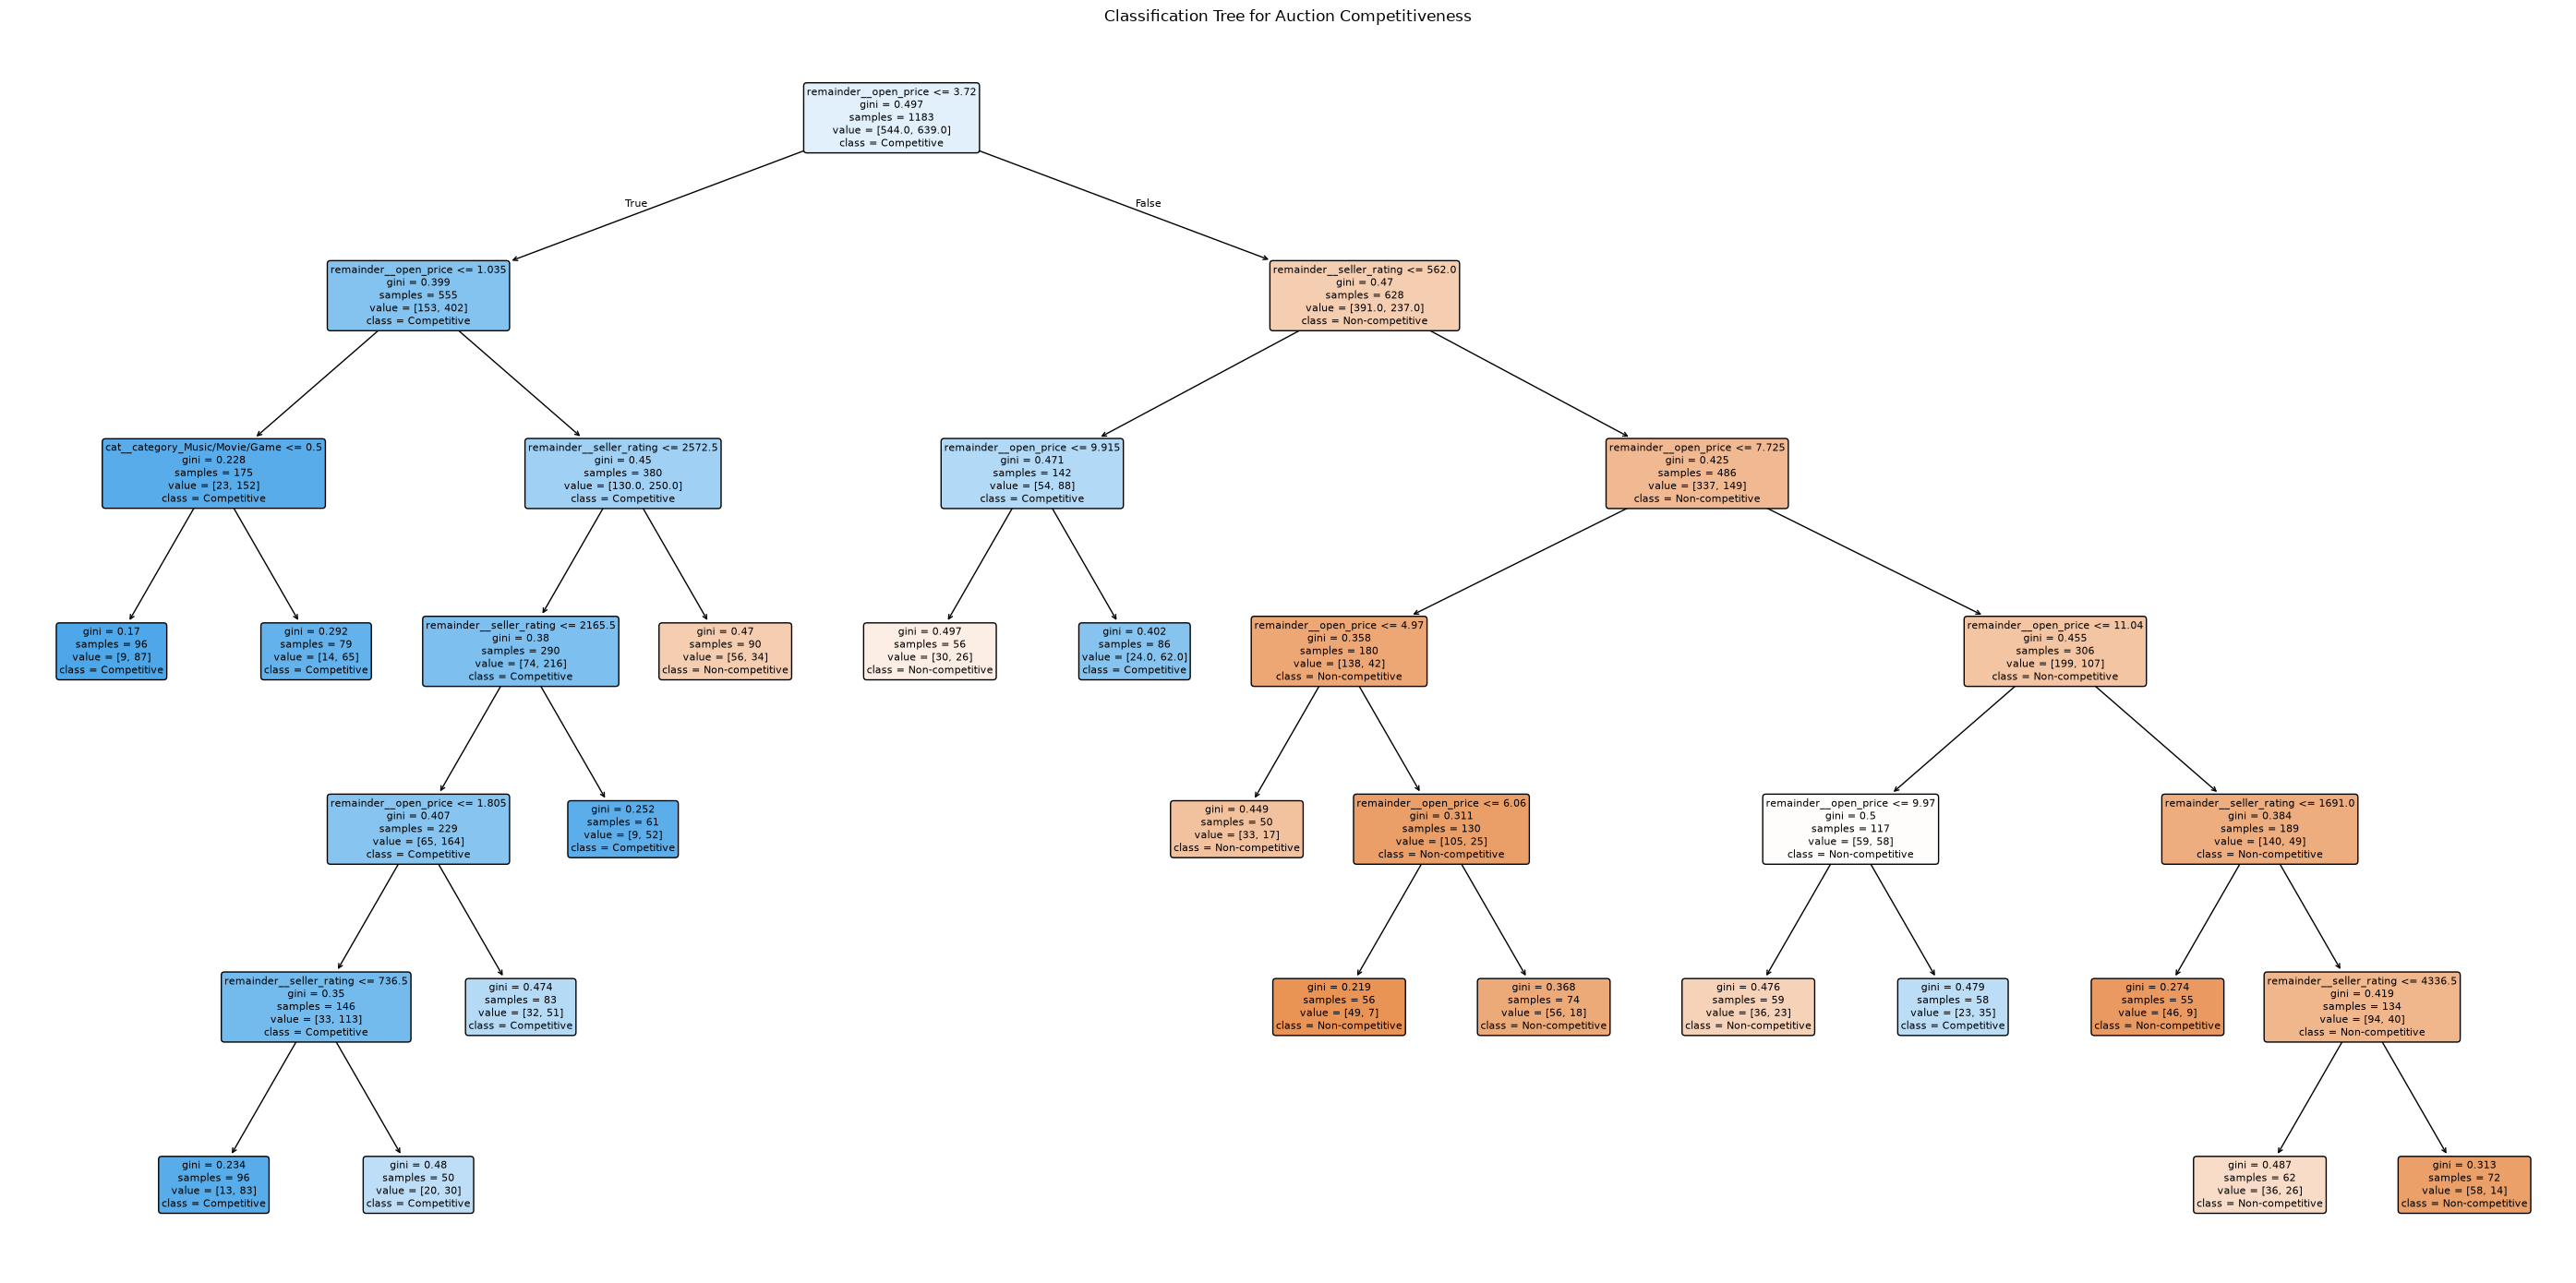

In [42]:
#Decision Tree
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(28, 14))

plot_tree(
    tree2,
    feature_names=tree2_feature_names,
    class_names=["Non-competitive", "Competitive"],
    filled=True,
    rounded=True,
    fontsize=8,
    proportion=False)

plt.title("Classification Tree for Auction Competitiveness")

plt.tight_layout()
plt.show()

### Tree Diagram Interpretation

- Opening Price is the primary predictor, with a root split at 3.72.
- Auctions with opening prices ≤ 3.72 have a higher competitive rate (72.4%) than those above 3.72 (37.7%).
- Seller Rating provides additional splits, suggesting its predictive role varies across price ranges.
- Other auction settings play a limited role in this fitted tree.

### Scatter Plot with Decision Tree Splits

Opening Price and Seller Rating were selected as the two quantitative predictors because they account for most of the splits in the fitted tree.

The scatter plot visualizes competitive and non-competitive auctions, with decision boundaries corresponding to the tree's split thresholds.

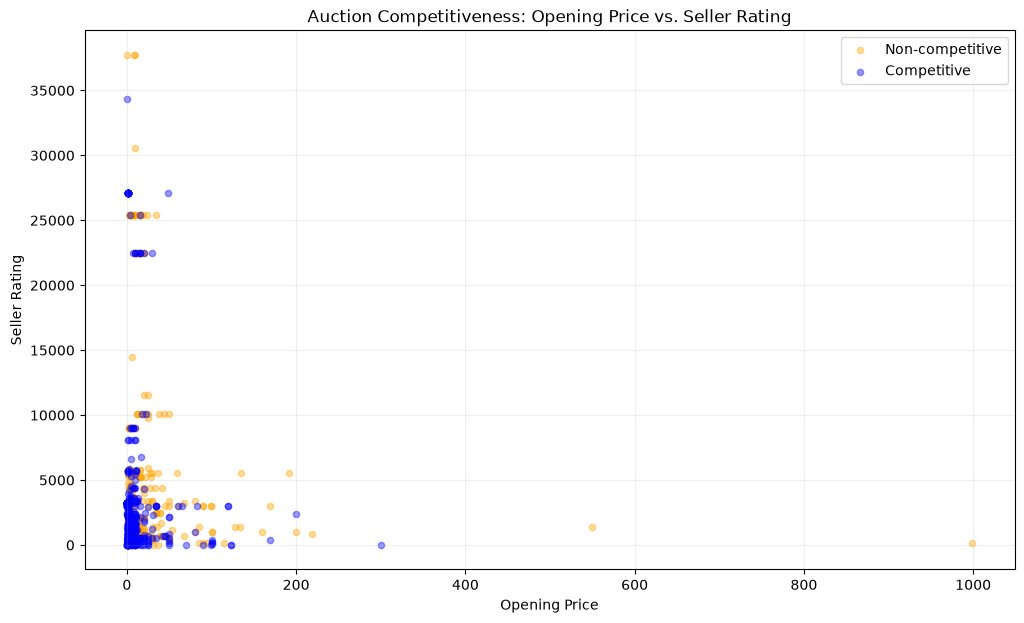

In [43]:
import matplotlib.pyplot as plt

#Extract two quantitative predictors
open_price = X_train["open_price"]
seller_rating = X_train["seller_rating"]

#Create scatter plot
plt.figure(figsize=(12, 7))

plt.scatter(
    open_price[y_train == 0],
    seller_rating[y_train == 0],
    c="orange",
    label="Non-competitive",
    alpha=0.4,
    s=20)

plt.scatter(
    open_price[y_train == 1],
    seller_rating[y_train == 1],
    c="blue",
    label="Competitive",
    alpha=0.4,
    s=20)

plt.xlabel("Opening Price")
plt.ylabel("Seller Rating")
plt.title("Auction Competitiveness: Opening Price vs. Seller Rating")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

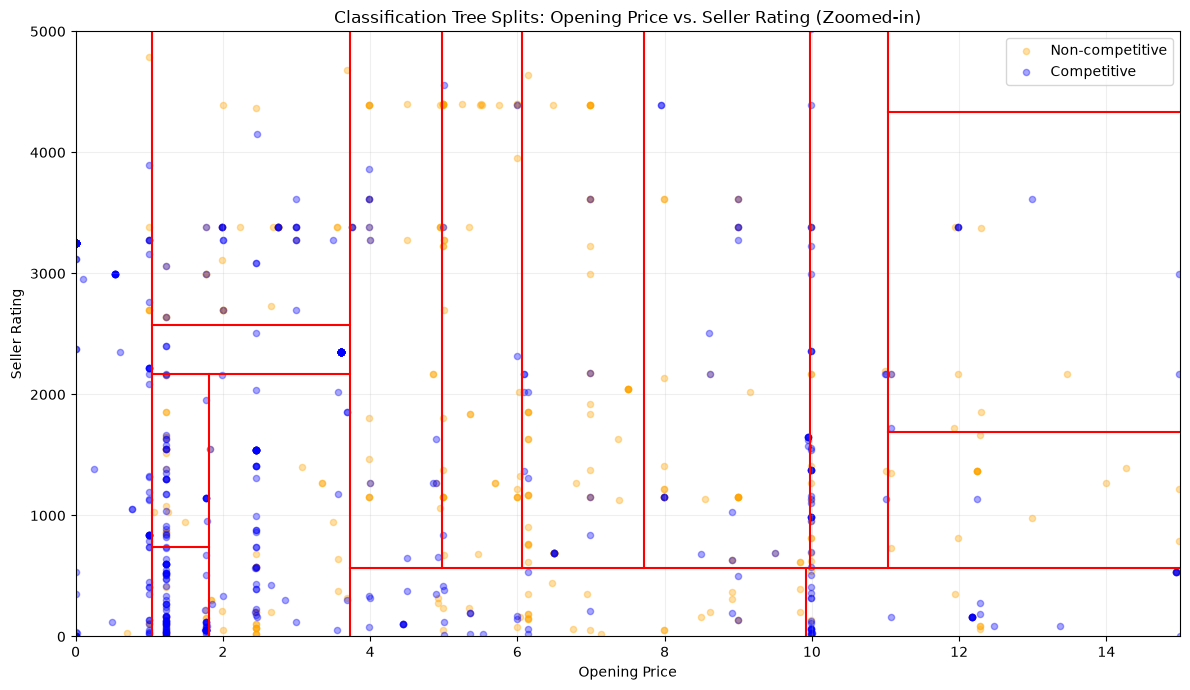

In [44]:
from sklearn.tree import _tree

#Feature indices for the two quantitative predictors
x_idx = list(tree2_feature_names).index("remainder__open_price")
y_idx = list(tree2_feature_names).index("remainder__seller_rating")

fig, ax = plt.subplots(figsize=(12, 7))

#Plot observations
for cls, color, label in [
    (0, "orange", "Non-competitive"),
    (1, "blue", "Competitive")
]:
    mask = (y_train == cls)

    ax.scatter(
        X_train.loc[mask, "open_price"],
        X_train.loc[mask, "seller_rating"],
        c=color,
        label=label,
        alpha=0.35,
        s=20)

# Set plot boundaries
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()

tree = tree2.tree_

def draw_splits(node, xmin, xmax, ymin, ymax):
    # Stop at terminal nodes
    if tree.feature[node] == _tree.TREE_UNDEFINED:
        return

    feature = tree.feature[node]
    threshold = tree.threshold[node]

    left = tree.children_left[node]
    right = tree.children_right[node]

    if feature == x_idx:
        ax.plot(
            [threshold, threshold],
            [ymin, ymax],
            color="red",
            linewidth=1.5
        )

        draw_splits(left, xmin, threshold, ymin, ymax)
        draw_splits(right, threshold, xmax, ymin, ymax)

    elif feature == y_idx:
        ax.plot(
            [xmin, xmax],
            [threshold, threshold],
            color="red",
            linewidth=1.5
        )

        draw_splits(left, xmin, xmax, ymin, threshold)
        draw_splits(right, xmin, xmax, threshold, ymax)

    else:
        # Categorical split cannot be shown on these two axes
        # Continue exploring both branches
        draw_splits(left, xmin, xmax, ymin, ymax)
        draw_splits(right, xmin, xmax, ymin, ymax)

draw_splits(
    0,
    x_min, x_max,
    y_min, y_max)

ax.set_xlim(0, 15)
ax.set_ylim(0, 5000)

ax.set_xlabel("Opening Price")
ax.set_ylabel("Seller Rating")
ax.set_title("Classification Tree Splits: Opening Price vs. Seller Rating (Zoomed-in)")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

### Scatter Plot Interpretation

- Most decision tree splits occur at relatively low opening prices.
- Opening Price and Seller Rating create several local decision boundaries.
- Competitive and non-competitive auctions still overlap, indicating imperfect class separation.
- The plot is zoomed in for readability; observations outside the displayed range remain in model training.
- The categorical split is not fully represented in this two-dimensional visualization.

### Model Evaluation of Practical Decision Tree

We evaluate the practical decision tree using test accuracy and a classification table. The results are then compared with those of k-NN.

In [45]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd

# Evaluate the fitted practical decision tree
practical_tree_train_pred = tree2.predict(X_train_tree2)
practical_tree_test_pred = tree2.predict(X_test_tree2)
practical_tree_train_acc = accuracy_score(y_train, practical_tree_train_pred)
practical_tree_test_acc = accuracy_score(y_test, practical_tree_test_pred)

print(f"Practical Tree training accuracy: {practical_tree_train_acc:.2%}")
print(f"Practical Tree testing accuracy:  {practical_tree_test_acc:.2%}")

class_labels = ["Non-competitive", "Competitive"]
practical_tree_table = pd.DataFrame(
    confusion_matrix(y_test, practical_tree_test_pred, labels=[0, 1]),
    index=pd.Index(class_labels, name="Actual"),
    columns=pd.Index(class_labels, name="Predicted")
)
print("\nPractical Decision Tree classification table:")
display(practical_tree_table)
print("\nPractical Decision Tree classification report:")
print(classification_report(y_test, practical_tree_test_pred, labels=[0, 1],
                            target_names=class_labels, zero_division=0))

Practical Tree training accuracy: 73.12%
Practical Tree testing accuracy:  73.13%

Practical Decision Tree classification table:


Predicted,Non-competitive,Competitive
Actual,,
Non-competitive,269,93
Competitive,119,308



Practical Decision Tree classification report:
                 precision    recall  f1-score   support

Non-competitive       0.69      0.74      0.72       362
    Competitive       0.77      0.72      0.74       427

       accuracy                           0.73       789
      macro avg       0.73      0.73      0.73       789
   weighted avg       0.73      0.73      0.73       789



### Model  findings and seller advice

**What the splits tell us**

The lower-price side of the first split had more competitive auctions. In the training data, 402 of 555 auctions that opened at 3.72 or less got at least two bids (72.4%). Above 3.72, the share fell to 237 of 628 (37.7%). A lower price may make it easier for someone to place the first bid. Seller rating also helped within some price groups. For example, at an opening price of 2, the tree predicts at least two bids for a seller rated 2,000 and one bid for a seller rated 3,000.

On the scatter plot, both types of auction appear in many of the same boxes. This shows why the splits are useful but imperfect. Two items can have similar opening prices and seller ratings and still attract different numbers of bids.

**How well the tree predicts**

The tree correctly predicted 577 of the 789 test auctions (73.13%). Simply guessing that every auction would get at least two bids would have given 427 correct guesses (54.12%). The tree made 150 more correct predictions. It missed 119 auctions that did get a second bid. For a seller, the other mistake matters too. Of the 401 listings expected to get at least two bids, 93 ended with only one.

**What a seller should do**

Opening price is the first setting we would test. A seller could try a lower starting price on similar items listed in the same currency, as long as they would accept that price if only one bid came in. The workbook records prices in each listing’s currency, so 3.72 is a cutoff in these data. Its value differs in dollars, pounds, and euros.

The tree did not use duration, ending day, or currency in any split. It gives us no clear reason to run an auction longer, end it on a certain day, or change its currency to attract a second bid. For a small trial today, we would record both how often an item gets a second bid and its final selling price. The data come from 2004, and more bids alone do not guarantee a better sale price.

## [4]: k-NN Classification and Model Comparison

### 4A. Prepare the predictors for k-NN

We use the same 60/40 train-test split as the decision trees and exclude `close_price`, which is not known before an auction ends. One-hot encoding is applied to categorical predictors, while numerical predictors are standardized using training-set statistics only. This avoids data leakage during preprocessing.

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import pandas as pd
import matplotlib.pyplot as plt

# Same observations and split as the decision trees excluding closing price
knn_features = ["category", "currency", "seller_rating", "duration", "end_day", "open_price"]
X_train_knn = X_train[knn_features].copy()
X_test_knn = X_test[knn_features].copy()

knn_categorical = ["category", "currency", "duration", "end_day"]
knn_numerical = ["seller_rating", "open_price"]

knn_preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), knn_categorical),
        ("num", StandardScaler(), knn_numerical)
    ]
)

knn_pipeline = Pipeline([
    ("preprocess", knn_preprocessor),
    ("knn", KNeighborsClassifier())
])
print("k-NN training shape:", X_train_knn.shape)
print("k-NN testing shape:", X_test_knn.shape)

k-NN training shape: (1183, 6)
k-NN testing shape: (789, 6)


### 4B. Select k and voting weights using 5-fold cross-validation

We tune both the number of neighbors and the voting scheme (`uniform` versus `distance`) using only the training set. The preprocessing pipeline is fitted separately within each cross-validation fold to avoid data leakage.

Best k: 29
Best weights: distance
Best mean 5-fold CV accuracy: 0.6796


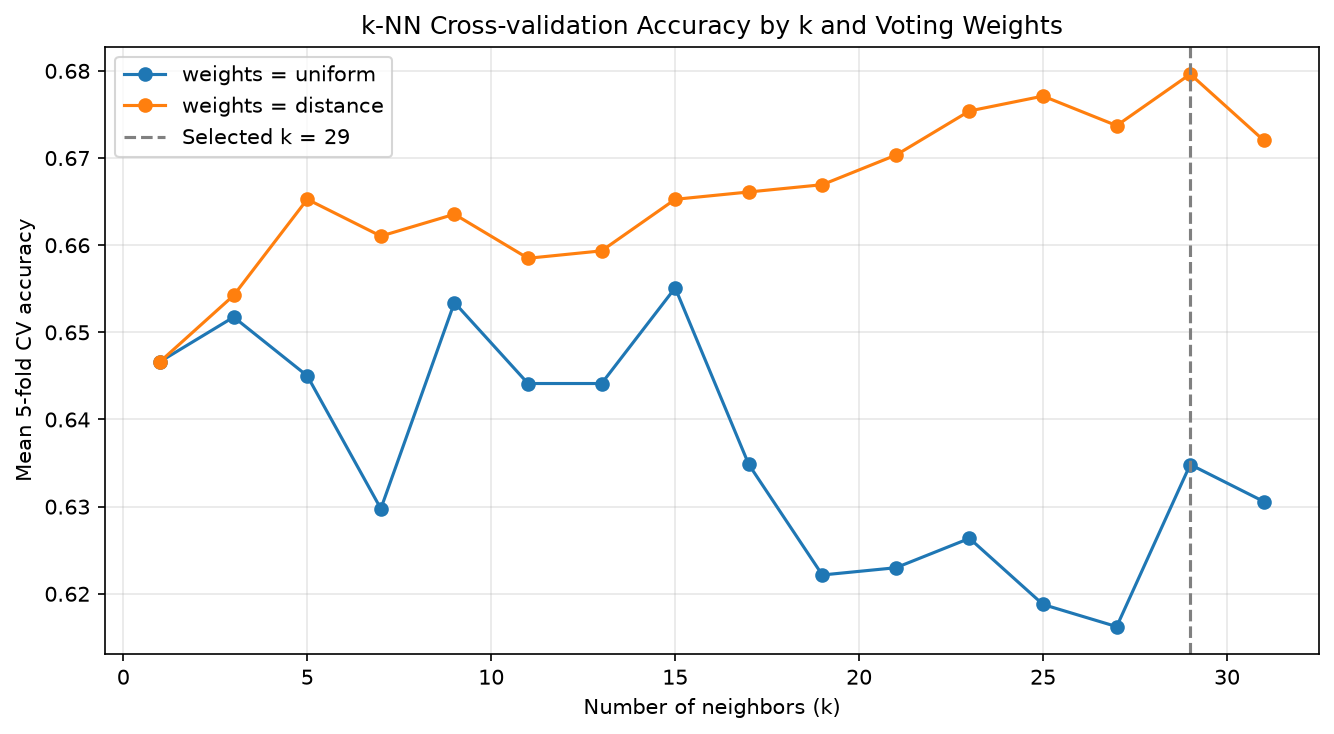

In [47]:
k_values = list(range(1, 32, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={
        "knn__n_neighbors": k_values,
        "knn__weights": ["uniform", "distance"]
    },
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)
knn_search.fit(X_train_knn, y_train)

best_knn = knn_search.best_estimator_
best_k = knn_search.best_params_["knn__n_neighbors"]
best_weights = knn_search.best_params_["knn__weights"]
print("Best k:", best_k)
print("Best weights:", best_weights)
print("Best mean 5-fold CV accuracy:", round(knn_search.best_score_, 4))

cv_results = pd.DataFrame(knn_search.cv_results_)
plt.figure(figsize=(9, 5))
for weight in ["uniform", "distance"]:
    subset = cv_results[cv_results["param_knn__weights"] == weight]
    plt.plot(
        subset["param_knn__n_neighbors"].astype(int),
        subset["mean_test_score"],
        marker="o",
        label=f"weights = {weight}"
    )
plt.axvline(best_k, linestyle="--", color="gray", label=f"Selected k = {best_k}")
plt.xlabel("Number of neighbors (k)")
plt.ylabel("Mean 5-fold CV accuracy")
plt.title("k-NN Cross-validation Accuracy by k and Voting Weights")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("knn_cv_accuracy.png", dpi=150, bbox_inches="tight")
from IPython.display import display, Image
display(Image(filename="knn_cv_accuracy.png"))
plt.close()


### 4C. Evaluate k-NN on the held-out test set

After selecting k and voting weights, we evaluate the selected model once on the untouched test set.

In [48]:
knn_train_pred = best_knn.predict(X_train_knn)
knn_test_pred = best_knn.predict(X_test_knn)

knn_train_acc = accuracy_score(y_train, knn_train_pred)
knn_test_acc = accuracy_score(y_test, knn_test_pred)
print(f"k-NN training accuracy: {knn_train_acc:.4f}")
print(f"k-NN testing accuracy:  {knn_test_acc:.4f}")
print("k-NN confusion matrix:")
knn_table = pd.DataFrame(
    confusion_matrix(y_test, knn_test_pred, labels=[0, 1]),
    index=pd.Index(["Non-competitive", "Competitive"], name="Actual"),
    columns=pd.Index(["Non-competitive", "Competitive"], name="Predicted")
)

display(knn_table)
print("\nk-NN classification report:")
print(classification_report(y_test, knn_test_pred, labels=[0, 1],
                            target_names=["Non-competitive", "Competitive"],
                            zero_division=0))

k-NN training accuracy: 0.9248
k-NN testing accuracy:  0.7098
k-NN confusion matrix:


Predicted,Non-competitive,Competitive
Actual,,
Non-competitive,231,131
Competitive,98,329



k-NN classification report:
                 precision    recall  f1-score   support

Non-competitive       0.70      0.64      0.67       362
    Competitive       0.72      0.77      0.74       427

       accuracy                           0.71       789
      macro avg       0.71      0.70      0.71       789
   weighted avg       0.71      0.71      0.71       789



### 4D. Compare k-NN with the practical decision tree

Both models use the same held-out observations and predictors available before the auction ends. The initial tree is shown for reference only, since it uses `close_price` and is not a fair deployable benchmark.

In [49]:
# Side-by-side comparison on the identical test observations
knn_table = pd.DataFrame(
    confusion_matrix(y_test, knn_test_pred, labels=[0, 1]),
    index=pd.Index(class_labels, name="Actual"),
    columns=pd.Index(class_labels, name="Predicted")
)

comparison = pd.DataFrame({
    "Model": [
        "Practical Decision Tree",
        f"k-NN (k={best_k}, weights={best_weights})"
    ],
    "Training Accuracy": [
        practical_tree_train_acc,
        knn_train_acc
    ],
    "Testing Accuracy": [
        practical_tree_test_acc,
        knn_test_acc
    ]
})

print("Accuracy comparison:")

comparison_display = comparison.copy()
comparison_display["Training Accuracy"] = comparison_display["Training Accuracy"].map("{:.2%}".format)
comparison_display["Testing Accuracy"] = comparison_display["Testing Accuracy"].map("{:.2%}".format)

display(comparison_display)

print("\nPractical Decision Tree classification table:")
display(practical_tree_table)

print("\nk-NN classification table:")
display(knn_table)

accuracy_difference = knn_test_acc - practical_tree_test_acc

print(f"\nk-NN minus Practical Tree test accuracy: {accuracy_difference:+.2%}")

if accuracy_difference > 0:
    print("k-NN is more accurate on the held-out test set.")
elif accuracy_difference < 0:
    print("The practical decision tree is more accurate on the held-out test set.")
else:
    print("Both models have equal held-out test accuracy.")


Accuracy comparison:


,Model,Training Accuracy,Testing Accuracy
0,Practical Decision Tree,73.12%,73.13%
1,"k-NN (k=29, weights=distance)",92.48%,70.98%



Practical Decision Tree classification table:


Predicted,Non-competitive,Competitive
Actual,,
Non-competitive,269,93
Competitive,119,308



k-NN classification table:


Predicted,Non-competitive,Competitive
Actual,,
Non-competitive,231,131
Competitive,98,329



k-NN minus Practical Tree test accuracy: -2.15%
The practical decision tree is more accurate on the held-out test set.


### 4E. Interpretation from the comparison

The practical decision tree is more interpretable because it provides classification rules based on auction characteristics, such as opening price and seller rating. These rules are easier for sellers to understand than k-NN, which classifies auctions based on their similarity to other observations.

The practical decision tree also performed slightly better on the test set, achieving 73.13% accuracy compared with 70.98% for k-NN (k = 29, distance weighting). However, k-NN achieved a much higher training accuracy of 92.48%, suggesting possible overfitting. In contrast, the decision tree had similar training and testing accuracies (73.12% and 73.13%), indicating more consistent performance across the two datasets.

From a business perspective, the decision tree is more useful because its rules can help sellers understand how auction settings, particularly opening price, relate to competitiveness. Although k-NN can make predictions based on similar auctions, it is harder to translate those predictions into specific recommendations. Therefore, the practical decision tree is preferable for this dataset because it offers slightly better test accuracy and clearer insights for sellers.